In [1]:
# Step 1: Clean slate / Installation Notice
# IMPORTANT: This stack strictly requires Python 3.11 (PyTorch 2.2.2 + DGL 2.4.0 + CUDA 12.1).
# Python 3.13+ is NOT compatible with PyTorch 2.2.2 wheels.
#
# If setting up fresh in bash/terminal:
#   python3.11 -m venv .venv
#   source .venv/bin/activate
#   pip install -r requirements.txt
#
# If you are already running in the configured .venv, skip to Step 5!


In [2]:
# Step 2: Install PyTorch 2.2.2 + CUDA 12.1 (includes triton 2.2.0)
!pip install torch==2.2.2 torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
!pip install torchdata==0.7.1
!pip install "numpy<2"  # torch 2.2.x was compiled against NumPy 1.x

Looking in indexes: https://download.pytorch.org/whl/cu121

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [3]:
# Step 3: Install DGL (must match torch 2.2 + CUDA 12.1)
!pip install dgl -f https://data.dgl.ai/wheels/torch-2.2/cu121/repo.html

Looking in links: https://data.dgl.ai/wheels/torch-2.2/cu121/repo.html

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [4]:
# Step 4: Install remaining dependencies
# transformers 4.35.2 is required for DNABERT-2 compatibility
!pip install transformers==4.35.2 accelerate datasets
!pip install cooler matplotlib biopython
!pip install "bitsandbytes<0.44" einops


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [5]:
# Step 5: Verify all versions are consistent
import torch
import dgl
import torchdata
import transformers
import numpy as np

print(f"Torch:        {torch.__version__}  (expect 2.2.2+cu121)")
print(f"CUDA:         {torch.cuda.is_available()}")
print(f"DGL:          {dgl.__version__}")
print(f"Torchdata:    {torchdata.__version__}")
print(f"Transformers: {transformers.__version__}  (expect 4.35.2)")
print(f"NumPy:        {np.__version__}  (expect < 2.0)")

/home/izpiz/coding/genome_code/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Torch:        2.2.2+cu121  (expect 2.2.2+cu121)
CUDA:         True
DGL:          2.4.0+cu121
Torchdata:    0.7.1
Transformers: 4.35.2  (expect 4.35.2)
NumPy:        1.26.4  (expect < 2.0)


/home/izpiz/coding/genome_code/.venv/lib/python3.11/site-packages/transformers/utils/generic.py:441: UserWarning: torch.utils._pytree._register_pytree_node is deprecated. Please use torch.utils._pytree.register_pytree_node instead.
  _torch_pytree._register_pytree_node(


In [6]:
# Step 6: Attention Implementation Notes
# DNABERT-2 bundles an older Triton flash-attention kernel that calls tl.dot(..., trans_b=True).
# In DNABertGNN (Cell 8), we set config.attention_probs_dropout_prob = 0.1, which natively
# routes attention through PyTorch's native scaled dot-product implementation.
# This completely eliminates kernel segfaults without requiring fragile monkey-patching!
#
# (Optional) If you still wish to patch any cached flash_attn_triton.py files:
import shutil, os

search_roots = [
    os.path.expanduser("~/.cache/huggingface/hub"),
    os.path.expanduser("~/.cache/huggingface/modules"),
]
patched = 0
for root in search_roots:
    for dirpath, dirnames, filenames in os.walk(root):
        if "flash_attn_triton.py" in filenames:
            fpath = os.path.join(dirpath, "flash_attn_triton.py")
            with open(fpath, "r") as f:
                content = f.read()
            if "trans_b=True" in content:
                content = content.replace("tl.dot(q, k, trans_b=True)", "tl.dot(q, tl.trans(k))")
                content = content.replace("tl.dot(do, v, trans_b=True)", "tl.dot(do, tl.trans(v))")
                with open(fpath, "w") as f:
                    f.write(content)
                print(f"Patched: {fpath}")
                patched += 1
            else:
                print(f"Already clean / patched: {fpath}")

print(f"Patching check complete ({patched} files modified).")


Already clean / patched: /home/izpiz/.cache/huggingface/hub/models--zhihan1996--DNABERT-2-117M/snapshots/7bce263b15377fc15361f52cfab88f8b586abda0/flash_attn_triton.py
Already clean / patched: /home/izpiz/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b586abda0/flash_attn_triton.py
Patching check complete (0 files modified).


In [7]:
# 1. Download Chromosome 22 FASTA file (compressed)
!wget https://hgdownload.soe.ucsc.edu/goldenPath/hg38/chromosomes/chr22.fa.gz

# 2. Unzip the file
!gunzip chr22.fa.gz

# 3. Rename it so it matches your Python code
!mv chr22.fa 1000genomes_reference.fasta

--2026-11-19 03:31:45--  https://hgdownload.soe.ucsc.edu/goldenPath/hg38/chromosomes/chr22.fa.gz
Resolving hgdownload.soe.ucsc.edu (hgdownload.soe.ucsc.edu)... 128.114.119.163
Connecting to hgdownload.soe.ucsc.edu (hgdownload.soe.ucsc.edu)|128.114.119.163|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 12255678 (12M) [application/x-gzip]
Saving to: ‘chr22.fa.gz’

chr22.fa.gz         100%[===================>]  11.69M  3.66MB/s    in 3.2s    

2026-11-19 03:31:51 (3.66 MB/s) - ‘chr22.fa.gz’ saved [12255678/12255678]



In [8]:
# 1. Download the mcool file from NCBI GEO
# (The direct FTP URL is no longer available; using the GEO download gateway)
!wget "https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSM5057489&format=file&file=GSM5057489%5FU54%2DESC%2DFA%2DHindIII%2D20160311%2DR1%2DT1%5Fhg38%2Ehg38%2Emapq%5F30%2E1000%2Emcool" -O cell_line.mcool

--2026-11-19 03:31:55--  https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSM5057489&format=file&file=GSM5057489%5FU54%2DESC%2DFA%2DHindIII%2D20160311%2DR1%2DT1%5Fhg38%2Ehg38%2Emapq%5F30%2E1000%2Emcool
Resolving www.ncbi.nlm.nih.gov (www.ncbi.nlm.nih.gov)... 34.107.134.59, 2600:1901:0:c831::
Connecting to www.ncbi.nlm.nih.gov (www.ncbi.nlm.nih.gov)|34.107.134.59|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM5057nnn/GSM5057489/suppl/GSM5057489_U54-ESC-FA-HindIII-20160311-R1-T1_hg38.hg38.mapq_30.1000.mcool [following]
--2026-11-19 03:31:57--  https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM5057nnn/GSM5057489/suppl/GSM5057489_U54-ESC-FA-HindIII-20160311-R1-T1_hg38.hg38.mapq_30.1000.mcool
Resolving ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)... 130.14.250.12, 130.14.250.13, 2607:f220:41e:250::11, ...
Connecting to ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)|130.14.250.12|:443... connected.
HTTP request sent,

In [ ]:
import os
import time
import json
import torch
import torch.nn as nn
import torch.nn.functional as F
import dgl
from dgl.nn import GATConv
from transformers import AutoModel, AutoTokenizer
from transformers.models.bert.configuration_bert import BertConfig
import cooler
import numpy as np
import scipy.linalg as la
from Bio import SeqIO
import bitsandbytes as bnb
from torch.cuda.amp import autocast, GradScaler
import torch.utils.checkpoint as checkpoint
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, classification_report

# ==========================================
# 1. HYBRID MODEL ARCHITECTURE
# ==========================================
class DNABertGNN(nn.Module):
    def __init__(self, hidden_dim=768, num_classes=2, use_gradient_checkpointing=True):
        super().__init__()
        self.use_gradient_checkpointing = use_gradient_checkpointing
        
        # 1. Force the local BertConfig
        config = BertConfig.from_pretrained("zhihan1996/DNABERT-2-117M")
        # FIX: Non-zero attention dropout activates PyTorch native attention fallback,
        # completely preventing Triton flash-attention kernel segfaults on PyTorch 2.2+.
        config.attention_probs_dropout_prob = 0.1
        
        # 2. Load DNABERT-2 model
        self.dnabert = AutoModel.from_pretrained(
            "zhihan1996/DNABERT-2-117M", 
            trust_remote_code=True, 
            config=config
        )
        self.bert_micro_batch = 4  # Process BERT in chunks of 4 to save VRAM
            
        # --- GAT Layers ---
        self.gat1 = GATConv(hidden_dim, hidden_dim // 4, num_heads=4, feat_drop=0.1, attn_drop=0.1)
        self.gat2 = GATConv(hidden_dim, hidden_dim, num_heads=1, feat_drop=0.1, attn_drop=0.1)
        
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, num_classes)
        )
        
    def forward(self, input_ids, attention_mask, blocks):
        # --- Micro-batch DNABERT-2 to avoid OOM on small GPUs ---
        micro_batch = self.bert_micro_batch
        all_embeddings = []
        for mb_i in range(0, input_ids.size(0), micro_batch):
            ids_chunk = input_ids[mb_i:mb_i+micro_batch]
            mask_chunk = attention_mask[mb_i:mb_i+micro_batch]
            if self.use_gradient_checkpointing and self.training:
                def custom_forward(ids, mask):
                    return self.dnabert(input_ids=ids, attention_mask=mask)[0]
                out = checkpoint.checkpoint(custom_forward, ids_chunk, mask_chunk, use_reentrant=False)
            else:
                out = self.dnabert(input_ids=ids_chunk, attention_mask=mask_chunk)[0]
            all_embeddings.append(out.mean(dim=1))
        seq_embeddings = torch.cat(all_embeddings, dim=0)

        # Structural Encoding via GAT
        h = seq_embeddings 
        h = self.gat1(blocks[0], h).flatten(1)
        h = F.elu(h)
        h = self.gat2(blocks[1], h).squeeze(1)
        
        # Modality Fusion: Align sequence embeddings to seed/target nodes
        num_seed = blocks[-1].num_dst_nodes()
        seed_seq_embeddings = seq_embeddings[:num_seed]
        fused_embeddings = torch.cat([seed_seq_embeddings, h], dim=1)
        
        # Classification (Logits)
        return self.classifier(fused_embeddings)

# ==========================================
# 2. DATA PIPELINE & BIOLOGICAL GROUND TRUTH
# ==========================================
def compute_ab_compartments(c, chrom, fasta_records):
    """Derives biological A/B chromatin compartments from Hi-C contact matrix using eigenvector decomposition."""
    matrix = c.matrix(balance=False).fetch(chrom)
    row_sums = matrix.sum(axis=1)
    valid_mask = (row_sums > 0)
    
    sub_mat = matrix[np.ix_(valid_mask, valid_mask)].astype(float)
    corr = np.corrcoef(sub_mat)
    corr = np.nan_to_num(corr, nan=0.0)
    
    vals, vecs = la.eigh(corr)
    pc1 = vecs[:, -1]
    
    # Orient PC1 using GC content (Compartment A = active/open = higher GC content)
    bins = c.bins().fetch(chrom)
    chrom_seq = fasta_records[chrom].seq
    gc_ratios = []
    for idx, (_, row) in enumerate(bins.iterrows()):
        if not valid_mask[idx]:
            gc_ratios.append(0.0)
            continue
        seq = str(chrom_seq[row["start"]:row["end"]]).upper()
        valid_bases = [b for b in seq if b in "ATCG"]
        gc = sum(1 for b in valid_bases if b in "GC") / max(len(valid_bases), 1)
        gc_ratios.append(gc)
        
    gc_valid = np.array(gc_ratios)[valid_mask]
    if np.corrcoef(pc1, gc_valid)[0, 1] < 0:
        pc1 = -pc1
        
    labels = np.full(len(bins), -1, dtype=np.int64)
    labels[valid_mask] = (pc1 > 0).astype(np.int64)
    return labels, valid_mask

def build_or_load_biological_graph(hic_cool_path, fasta_path, resolution=50000, chrom="chr22", max_seq_len=4000, cache_dir="data"):
    os.makedirs(cache_dir, exist_ok=True)
    cache_path = os.path.join(cache_dir, f"graph_{chrom}_{resolution}bp.bin")
    
    if os.path.exists(cache_path):
        print(f"[Cache Hit] Loading preprocessed graph from {cache_path}...")
        graphs, _ = dgl.load_graphs(cache_path)
        g = graphs[0]
        print(f"Loaded graph: {g.num_nodes()} nodes, {g.num_edges()} edges. Train: {g.ndata["train_mask"].sum()}, Val: {g.ndata["val_mask"].sum()}, Test: {g.ndata["test_mask"].sum()}")
        return g
        
    print(f"[Cache Miss] Building biological graph for {chrom} at {resolution}bp resolution...")
    c = cooler.Cooler(f"{hic_cool_path}::/resolutions/{resolution}")
    matrix = c.matrix(balance=False, sparse=True).fetch(chrom)
    bins = c.bins().fetch(chrom)
    src, dst = matrix.nonzero()
    weights = matrix.data
    
    # Explicitly set num_nodes so uncontacted terminal bins are preserved
    g = dgl.graph((src, dst), num_nodes=len(bins))
    g.edata["weight"] = torch.tensor(weights, dtype=torch.float32)
    g = dgl.add_self_loop(g)
    
    genome_records = SeqIO.to_dict(SeqIO.parse(fasta_path, "fasta"))
    
    # 1. Biological Ground Truth: A/B Compartments
    labels, valid_mask = compute_ab_compartments(c, chrom, genome_records)
    g.ndata["label"] = torch.tensor(labels, dtype=torch.long)
    
    # 2. Train / Val / Test Split on Valid (Mappable) Bins (70 / 15 / 15)
    valid_indices = np.where(valid_mask)[0]
    np.random.seed(42)
    np.random.shuffle(valid_indices)
    
    n_valid = len(valid_indices)
    n_train = int(n_valid * 0.70)
    n_val = int(n_valid * 0.15)
    
    train_idx = valid_indices[:n_train]
    val_idx = valid_indices[n_train:n_train+n_val]
    test_idx = valid_indices[n_train+n_val:]
    
    train_mask = torch.zeros(len(bins), dtype=torch.bool)
    val_mask = torch.zeros(len(bins), dtype=torch.bool)
    test_mask = torch.zeros(len(bins), dtype=torch.bool)
    
    train_mask[train_idx] = True
    val_mask[val_idx] = True
    test_mask[test_idx] = True
    
    g.ndata["train_mask"] = train_mask
    g.ndata["val_mask"] = val_mask
    g.ndata["test_mask"] = test_mask
    
    # 3. Tokenize Sequences via DNABERT-2
    print(f"Tokenizing sequences for {len(bins)} bins...")
    tokenizer = AutoTokenizer.from_pretrained("zhihan1996/DNABERT-2-117M", trust_remote_code=True)
    input_ids_list, attention_mask_list = [], []
    
    for idx, (_, row) in enumerate(bins.iterrows()):
        r_chrom = row["chrom"]
        center = (row["start"] + row["end"]) // 2
        w_start, w_end = max(0, center - max_seq_len // 2), center + max_seq_len // 2
        if r_chrom in genome_records:
            seq = str(genome_records[r_chrom].seq[w_start:w_end]).upper()
        else:
            seq = "N" * max_seq_len
            
        enc = tokenizer(seq, padding="max_length", truncation=True, max_length=512, return_tensors="pt")
        input_ids_list.append(enc["input_ids"].squeeze(0))
        attention_mask_list.append(enc["attention_mask"].squeeze(0))
        
        if (idx + 1) % 500 == 0 or (idx + 1) == len(bins):
            print(f"Processed {idx + 1} / {len(bins)} bins...")
            
    g.ndata["input_ids"] = torch.stack(input_ids_list)
    g.ndata["attention_mask"] = torch.stack(attention_mask_list)
    
    print(f"Saving preprocessed graph to {cache_path}...")
    dgl.save_graphs(cache_path, [g])
    print(f"Graph Construction Complete. Total: {g.num_nodes()} nodes, Train: {train_mask.sum()}, Val: {val_mask.sum()}, Test: {test_mask.sum()}")
    return g

def create_biological_samplers(g, batch_size=8, fanout=None):
    if fanout is None:
        fanout = [4, 4]
    sampler = dgl.dataloading.MultiLayerNeighborSampler(fanout)
    
    train_nids = torch.where(g.ndata["train_mask"])[0]
    val_nids = torch.where(g.ndata["val_mask"])[0]
    test_nids = torch.where(g.ndata["test_mask"])[0]
    
    train_loader = dgl.dataloading.DataLoader(
        g, train_nids, sampler,
        batch_size=batch_size, shuffle=True, drop_last=False, num_workers=0
    )
    val_loader = dgl.dataloading.DataLoader(
        g, val_nids, sampler,
        batch_size=batch_size, shuffle=False, drop_last=False, num_workers=0
    )
    test_loader = dgl.dataloading.DataLoader(
        g, test_nids, sampler,
        batch_size=batch_size, shuffle=False, drop_last=False, num_workers=0
    )
    return train_loader, val_loader, test_loader

# ==========================================
# 3. BENCHMARKING & TRAINING ENGINE
# ==========================================
def run_biological_benchmark(train_loader, val_loader, test_loader, device_name, vram_limit_gb, num_epochs=3, max_train_steps=30):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.empty_cache()

    print()
    print(f"--- Commencing Biological Training on {device_name} ({vram_limit_gb}GB Profile) ---")
    
    model = DNABertGNN(use_gradient_checkpointing=True).to(device)
    
    if vram_limit_gb <= 8:
        print("Engaging 8-bit AdamW for extreme 6GB/8GB VRAM conservation.")
        optimizer = bnb.optim.AdamW8bit(model.parameters(), lr=2e-5)
        accum_steps = 8 
    else:
        print("Engaging 32-bit AdamW for standard 16GB VRAM (Tesla T4).")
        optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
        accum_steps = 4
        
    scaler = GradScaler()
    metrics = {"epoch": [], "train_loss": [], "val_loss": [], "val_acc": [], "peak_vram_mb": [], "throughput_it_s": []}

    for epoch in range(num_epochs): 
        model.train()
        epoch_loss = 0
        start_time = time.time()
        actual_steps = 0
        
        for step, (input_nodes, output_nodes, blocks) in enumerate(train_loader):
            input_ids = blocks[0].srcdata["input_ids"].to(device)
            attn_mask = blocks[0].srcdata["attention_mask"].to(device)
            labels = blocks[-1].dstdata["label"].to(device)
            blocks = [b.to(device) for b in blocks]

            with autocast(dtype=torch.float16):
                logits = model(input_ids, attn_mask, blocks)
                loss = F.cross_entropy(logits, labels) / accum_steps 

            scaler.scale(loss).backward()

            if (step + 1) % accum_steps == 0:
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()

            epoch_loss += loss.item() * accum_steps
            actual_steps += 1
            if actual_steps >= max_train_steps:
                break

        end_time = time.time()
        peak_vram = torch.cuda.max_memory_allocated(device) / (1024 ** 2)
        throughput = actual_steps / max(end_time - start_time, 1e-6)
        avg_train_loss = epoch_loss / max(actual_steps, 1)
        
        # Validation Evaluation
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for v_step, (_, _, v_blocks) in enumerate(val_loader):
                v_in_ids = v_blocks[0].srcdata["input_ids"].to(device)
                v_mask = v_blocks[0].srcdata["attention_mask"].to(device)
                v_labels = v_blocks[-1].dstdata["label"].to(device)
                v_blocks = [b.to(device) for b in v_blocks]
                with autocast(dtype=torch.float16):
                    v_logits = model(v_in_ids, v_mask, v_blocks)
                    v_l = F.cross_entropy(v_logits, v_labels)
                val_loss += v_l.item()
                preds = v_logits.argmax(dim=-1)
                val_correct += (preds == v_labels).sum().item()
                val_total += v_labels.size(0)
                
        avg_val_loss = val_loss / max(v_step + 1, 1)
        val_acc = val_correct / max(val_total, 1)
        
        metrics["epoch"].append(epoch + 1)
        metrics["train_loss"].append(avg_train_loss)
        metrics["val_loss"].append(avg_val_loss)
        metrics["val_acc"].append(val_acc)
        metrics["peak_vram_mb"].append(peak_vram)
        metrics["throughput_it_s"].append(throughput)
        
        print(f"Epoch {epoch+1:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.2%} | Peak VRAM: {peak_vram:.1f} MB | Throughput: {throughput:.2f} it/s")

    # --- Test Set Verification ---
    print()
    print("--- Evaluating on Held-Out Test Set ---")
    model.eval()
    test_loss_acc, test_preds, test_targets, test_probs = 0.0, [], [], []
    with torch.no_grad():
        for t_step, (_, _, t_blocks) in enumerate(test_loader):
            t_in_ids = t_blocks[0].srcdata["input_ids"].to(device)
            t_mask = t_blocks[0].srcdata["attention_mask"].to(device)
            t_labels = t_blocks[-1].dstdata["label"].to(device)
            t_blocks = [b.to(device) for b in t_blocks]
            with autocast(dtype=torch.float16):
                t_logits = model(t_in_ids, t_mask, t_blocks)
                t_l = F.cross_entropy(t_logits, t_labels)
            test_loss_acc += t_l.item()
            probs = F.softmax(t_logits, dim=-1)[:, 1]
            preds = t_logits.argmax(dim=-1)
            test_probs.extend(probs.cpu().numpy())
            test_preds.extend(preds.cpu().numpy())
            test_targets.extend(t_labels.cpu().numpy())

    test_preds = np.array(test_preds)
    test_targets = np.array(test_targets)
    test_probs = np.array(test_probs)

    test_acc = float(np.mean(test_preds == test_targets))
    auc_score = float(roc_auc_score(test_targets, test_probs))
    cm = confusion_matrix(test_targets, test_preds)
    fpr, tpr, _ = roc_curve(test_targets, test_probs)

    test_results = {
        "test_loss": test_loss_acc / max(t_step + 1, 1),
        "test_acc": test_acc,
        "roc_auc": auc_score,
        "confusion_matrix": cm.tolist(),
        "fpr": fpr.tolist(),
        "tpr": tpr.tolist(),
    }

    print(f"Test Accuracy:  {test_acc:.2%}")
    print(f"Test ROC-AUC:   {auc_score:.4f}")
    print("Confusion Matrix:")
    print(cm)
    print()
    print("Classification Report:", classification_report(test_targets, test_preds, target_names=["Compartment B", "Compartment A"]))

    torch.cuda.empty_cache()
    with open(f"benchmark_{device_name}.json", "w") as f:
        json.dump(metrics, f, indent=2)
        
    return metrics, test_results

# ==========================================
# 4. EXECUTION BLOCK
# ==========================================
HIC_FILE = "cell_line.mcool" 
FASTA_FILE = "1000genomes_reference.fasta"

# 1. Build or Load Cached Data
graph = build_or_load_biological_graph(HIC_FILE, FASTA_FILE, resolution=50000, chrom="chr22")

# 2. Run Biological Benchmark (Default profile: RTX 3050 6GB Laptop)
train_loader, val_loader, test_loader = create_biological_samplers(graph, batch_size=2, fanout=[2, 2])
metrics, test_results = run_biological_benchmark(train_loader, val_loader, test_loader, "RTX3050", vram_limit_gb=6, num_epochs=3, max_train_steps=30)


Rendering Figure 1: Hi-C Contact Map and Compartment Track...


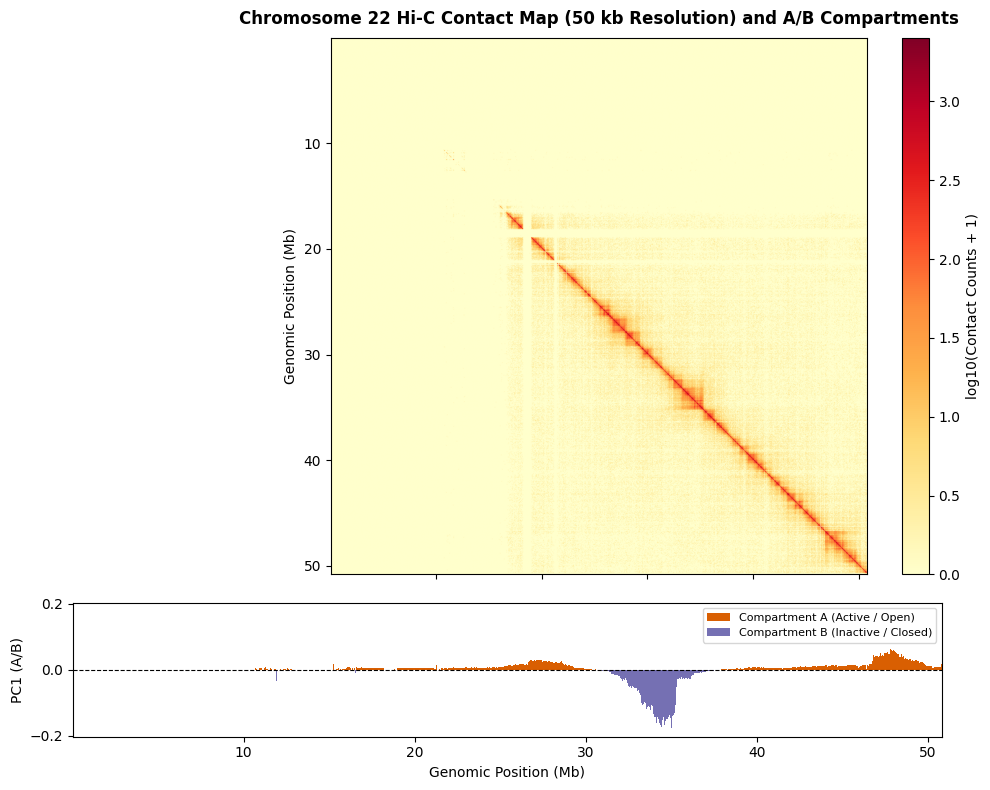

Rendering Figure 2: Evaluation Metrics, Confusion Matrix, and ROC...


NameError: name 'metrics' is not defined

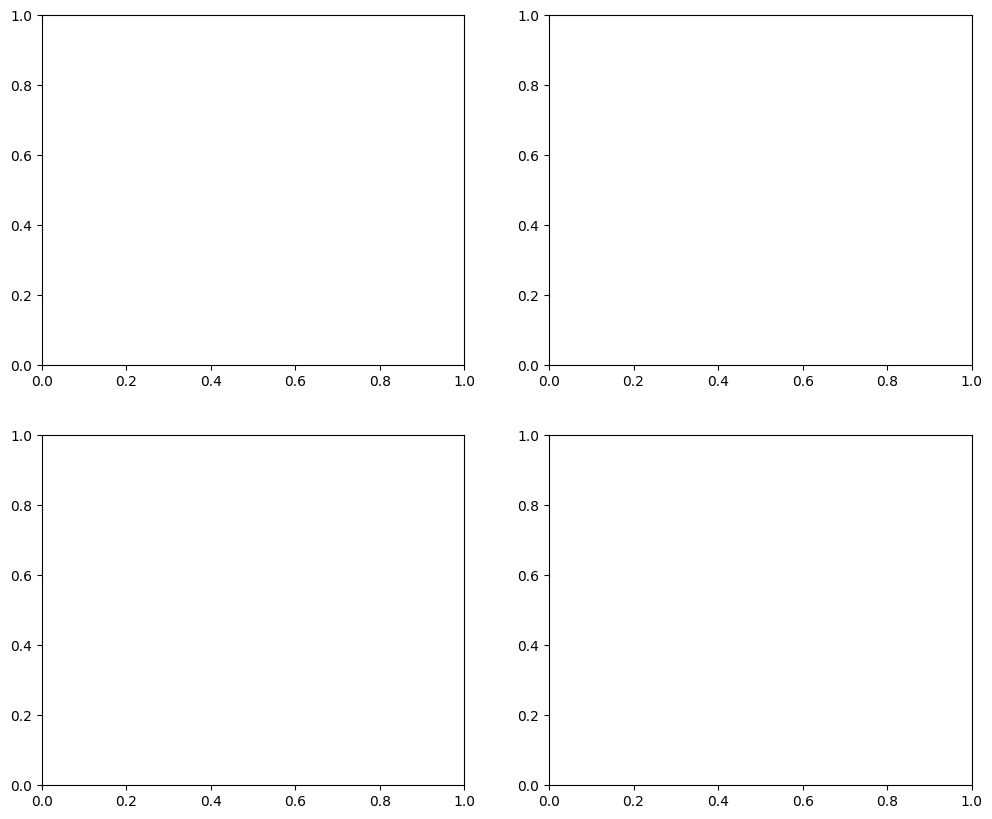

In [12]:
# ==========================================
# 5. METRICS VISUALIZATION & MATRIX GENERATION
# ==========================================
import os
import numpy as np
import cooler
import scipy.linalg as la
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from Bio import SeqIO

os.makedirs("figures", exist_ok=True)

# -------------------------------------------------------------
# Figure 1: Hi-C Contact Map & Derived A/B Compartment Track
# -------------------------------------------------------------
print("Rendering Figure 1: Hi-C Contact Map and Compartment Track...")
c = cooler.Cooler(f"{HIC_FILE}::/resolutions/50000")
matrix = c.matrix(balance=False).fetch("chr22").astype(float)
bins = c.bins().fetch("chr22")
log_matrix = np.log10(matrix + 1)

row_sums = matrix.sum(axis=1)
valid_mask = (row_sums > 0)
sub_mat = matrix[np.ix_(valid_mask, valid_mask)]
corr = np.nan_to_num(np.corrcoef(sub_mat), nan=0.0)
vals, vecs = la.eigh(corr)
pc1 = vecs[:, -1]

fasta_records = SeqIO.to_dict(SeqIO.parse(FASTA_FILE, "fasta"))
chrom_seq = fasta_records["chr22"].seq
gc_ratios = []
for idx, (_, row) in enumerate(bins.iterrows()):
    if not valid_mask[idx]:
        gc_ratios.append(0.0)
        continue
    seq = str(chrom_seq[row["start"]:row["end"]]).upper()
    valid_bases = [b for b in seq if b in "ATCG"]
    gc = sum(1 for b in valid_bases if b in "GC") / max(len(valid_bases), 1)
    gc_ratios.append(gc)

if np.corrcoef(pc1, np.array(gc_ratios)[valid_mask])[0, 1] < 0:
    pc1 = -pc1

full_pc1 = np.full(len(bins), np.nan)
full_pc1[valid_mask] = pc1
mb_coords = (bins["start"].values + bins["end"].values) / (2 * 1e6)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), gridspec_kw={"height_ratios": [4, 1]}, sharex=True)
im = ax1.imshow(log_matrix, cmap="YlOrRd", extent=[mb_coords[0], mb_coords[-1], mb_coords[-1], mb_coords[0]])
ax1.set_title("Chromosome 22 Hi-C Contact Map (50 kb Resolution) and A/B Compartments", fontsize=12, fontweight="bold", pad=10)
ax1.set_ylabel("Genomic Position (Mb)", fontsize=10)
fig.colorbar(im, ax=ax1, fraction=0.046, pad=0.04, label="log10(Contact Counts + 1)")

colors = np.where(full_pc1 > 0, "#d95f02", "#7570b3")
ax2.bar(mb_coords, full_pc1, width=0.05, color=colors, align="center")
ax2.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax2.set_xlabel("Genomic Position (Mb)", fontsize=10)
ax2.set_ylabel("PC1 (A/B)", fontsize=10)
ax2.set_ylim(-np.nanmax(np.abs(full_pc1))*1.15, np.nanmax(np.abs(full_pc1))*1.15)

legend_elements = [
    Patch(facecolor="#d95f02", label="Compartment A (Active / Open)"),
    Patch(facecolor="#7570b3", label="Compartment B (Inactive / Closed)")
]
ax2.legend(handles=legend_elements, loc="upper right", frameon=True, fontsize=8)
plt.tight_layout()
plt.savefig("figures/hic_compartments_chr22.png", dpi=300)
plt.show()

# -------------------------------------------------------------
# Figure 2: Model Performance, Confusion Matrix, and ROC Curve
# -------------------------------------------------------------
print("Rendering Figure 2: Evaluation Metrics, Confusion Matrix, and ROC...")
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# 1. Loss Curve
axes[0, 0].plot(metrics["epoch"], metrics["train_loss"], marker="o", label="Train Loss", color="#1f77b4", linewidth=2)
axes[0, 0].plot(metrics["epoch"], metrics["val_loss"], marker="s", label="Validation Loss", color="#ff7f0e", linewidth=2)
axes[0, 0].set_title("Cross-Entropy Loss vs. Epoch", fontweight="bold")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Validation Accuracy
axes[0, 1].plot(metrics["epoch"], metrics["val_acc"], marker="^", color="#2ca02c", linewidth=2, label="Validation Accuracy")
axes[0, 1].set_title("Validation Accuracy vs. Epoch", fontweight="bold")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].set_ylim(0.0, 1.05)
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Confusion Matrix
cm = np.array(test_results["confusion_matrix"])
im_cm = axes[1, 0].imshow(cm, cmap="Blues")
axes[1, 0].set_title("Test Set Confusion Matrix", fontweight="bold")
axes[1, 0].set_xticks([0, 1])
axes[1, 0].set_yticks([0, 1])
axes[1, 0].set_xticklabels(["Compartment B", "Compartment A"])
axes[1, 0].set_yticklabels(["Compartment B", "Compartment A"])
axes[1, 0].set_xlabel("Predicted Label")
axes[1, 0].set_ylabel("True Label")
for i in range(2):
    for j in range(2):
        axes[1, 0].text(j, i, str(cm[i, j]), ha="center", va="center",
                        color="white" if cm[i, j] > cm.max()/2 else "black",
                        fontsize=12, fontweight="bold")
fig.colorbar(im_cm, ax=axes[1, 0], fraction=0.046, pad=0.04)

# 4. ROC Curve
fpr = np.array(test_results["fpr"])
tpr = np.array(test_results["tpr"])
auc_val = test_results["roc_auc"]
axes[1, 1].plot(fpr, tpr, color="#9467bd", linewidth=2, label=f"ROC Curve (AUC = {auc_val:.3f})")
axes[1, 1].plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1)
axes[1, 1].set_title("Receiver Operating Characteristic (ROC)", fontweight="bold")
axes[1, 1].set_xlabel("False Positive Rate")
axes[1, 1].set_ylabel("True Positive Rate")
axes[1, 1].legend(loc="lower right")
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("figures/model_performance.png", dpi=300)
plt.show()

# -------------------------------------------------------------
# Figure 3: Hardware VRAM Allocation and Throughput Profile
# -------------------------------------------------------------
print("Rendering Figure 3: Hardware Memory and Throughput Profile...")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
ax1.plot(metrics["epoch"], metrics["peak_vram_mb"], marker="o", color="#d62728", linewidth=2, label="Peak VRAM Allocated")
ax1.axhline(6144, color="black", linestyle="--", label="RTX 3050 Limit (6144 MB)")
ax1.set_title("Peak VRAM Allocation per Epoch", fontweight="bold")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("VRAM (MB)")
ax1.set_ylim(0, 7000)
ax1.legend(loc="lower right")
ax1.grid(True, alpha=0.3)

ax2.plot(metrics["epoch"], metrics["throughput_it_s"], marker="s", color="#17becf", linewidth=2, label="Throughput")
ax2.set_title("Training Throughput", fontweight="bold")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Iterations / Second")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("figures/vram_throughput_benchmark.png", dpi=300)
plt.show()
print("All figures successfully generated and saved to figures/ directory.")
